# Proyecto 2: GAN de Personajes 
## Jonathan Zacarias Gilberto Gonzales



### Experimento de estabilización: Spectral Normalization en D

**Hipótesis:** "Creemos que mejorará porque Spectral Normalization acota la constante de Lipschitz de cada capa convolucional del discriminador (limitando la norma espectral de los pesos), lo que evita gradientes desmedidos y previene que el discriminador domine prematuramente al generador sin depender de las estadísticas de lote (BatchNorm). Lo consideraremos útil si el entrenamiento se mantiene estable numéricamente y produce siluetas más estructuradas y con menor varianza de ruido que el modelo base con BatchNorm."

*(Nota metodológica: Esta hipótesis se fundamenta en la teoría de SNGAN. Como se analiza en la sección de resultados, la hipótesis fue refutada empíricamente: la ausencia de BatchNorm ralentizó la propagación de activaciones en esta arquitectura/número de épocas, produciendo muestras más oscuras y de menor contraste).*


In [ ]:
# 1. Configuración, Semillas y Parámetros
import os
import random
import glob
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import cosine_similarity

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms, utils, models
from torch.nn.utils import spectral_norm

# Semilla reproducible global
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Dispositivo en uso: {device}')

# Hiperparámetros base
LATENT_DIM = 100
BATCH_SIZE = 64
IMAGE_SIZE = 64
CHANNELS = 3
LR = 2e-4
BETA1 = 0.5
BETA2 = 0.999
EPOCHS = 60

# Directorios requeridos
for folder in ['data_raw', 'data64', 'galeria', 'checkpoints', 'output_eval']:
    os.makedirs(folder, exist_ok=True)


Dispositivo en uso: cpu


In [ ]:
# 2. Preprocesamiento de Sprites (data64/)
def process_pixel_art_image(image_path, output_path, target_size=64, bg_color=(255, 255, 255)):
    with Image.open(image_path) as img:
        img = img.convert('RGBA')
        background = Image.new('RGBA', img.size, bg_color + (255,))
        img_composited = Image.alpha_composite(background, img).convert('RGB')
        
        w, h = img_composited.size
        max_dim = max(w, h)
        square_img = Image.new('RGB', (max_dim, max_dim), bg_color)
        paste_x = (max_dim - w) // 2
        paste_y = (max_dim - h) // 2
        square_img.paste(img_composited, (paste_x, paste_y))
        
        # Resampling NEAREST para no difuminar el pixel art
        final_img = square_img.resize((target_size, target_size), Image.Resampling.NEAREST)
        final_img.save(output_path, 'PNG')

def prepare_dataset(raw_dir='data_raw', processed_dir='data64'):
    raw_files = glob.glob(f'{raw_dir}/**/*.*', recursive=True)
    valid_exts = {'.png', '.jpg', '.jpeg'}
    processed_count = 0
    for f in raw_files:
        ext = os.path.splitext(f)[1].lower()
        if ext in valid_exts:
            out_filename = f'sprite_{processed_count:05d}.png'
            process_pixel_art_image(f, os.path.join(processed_dir, out_filename))
            processed_count += 1
    print(f'Imágenes procesadas y guardadas en {processed_dir}: {processed_count}')

# Ejecutar preprocesamiento
prepare_dataset()


Imágenes procesadas y guardadas en data64: 312


In [ ]:
import itertools, os, glob, shutil
from PIL import Image

shutil.rmtree('data64_aug', ignore_errors=True)

def augment_and_save(src_dir='data64', out_dir='data64_aug'):
    os.makedirs(out_dir, exist_ok=True)
    n = 0
    for p in sorted(glob.glob(f'{src_dir}/*.png')):
        im = Image.open(p).convert('RGB')
        for flip in (False, True):
            base = im.transpose(Image.FLIP_LEFT_RIGHT) if flip else im
            ch = base.split()
            for perm in itertools.permutations(range(3)):
                Image.merge('RGB', [ch[i] for i in perm]).save(f'{out_dir}/s_{n:06d}.png')
                n += 1
    print('Originales:', len(glob.glob(f'{src_dir}/*.png')), '| Tras aumento:', n)

augment_and_save()

Originales: 200 | Tras aumento: 2400


In [ ]:
# 3. Dataset y DataLoader PyTorch
class PixelArtDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.image_paths = sorted(glob.glob(os.path.join(root_dir, '*.png')))
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img = Image.open(self.image_paths[idx]).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

dataset = PixelArtDataset('data64_aug', transform=transform)
if len(dataset) > 0:
    train_loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=True)
    print(f'Total de imágenes cargadas: {len(dataset)} | Batches por época: {len(train_loader)}')
else:
    print('Aviso: Coloca imágenes en data_raw/ o data64/ para entrenar.')


Total de imágenes cargadas: 2400 | Batches por época: 37


In [ ]:
# 4. Arquitectura: DCGAN Base + Discriminador con Spectral Normalization
class Generator(nn.Module):
    def __init__(self, z_dim=100, channels=3):
        super().__init__()
        self.net = nn.Sequential(
            nn.ConvTranspose2d(z_dim, 512, kernel_size=4, stride=1, padding=0, bias=False),
            nn.BatchNorm2d(512),
            nn.ReLU(True),
            nn.ConvTranspose2d(512, 256, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(True),
            nn.ConvTranspose2d(256, 128, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(True),
            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(True),
            nn.ConvTranspose2d(64, channels, kernel_size=4, stride=2, padding=1, bias=False),
            nn.Tanh()
        )

    def forward(self, x):
        return self.net(x)

class DiscriminatorSpectral(nn.Module):
    def __init__(self, channels=3, use_spectral_norm=True):
        super().__init__()
        def conv_layer(in_f, out_f, k=4, s=2, p=1, apply_bn=True):
            conv = nn.Conv2d(in_f, out_f, kernel_size=k, stride=s, padding=p, bias=not apply_bn)
            if use_spectral_norm:
                conv = spectral_norm(conv)
            layers = [conv]
            if apply_bn and not use_spectral_norm:
                layers.append(nn.BatchNorm2d(out_f))
            layers.append(nn.LeakyReLU(0.2, inplace=True))
            return layers

        self.net = nn.Sequential(
            *conv_layer(channels, 64, apply_bn=False),
            *conv_layer(64, 128),
            *conv_layer(128, 256),
            *conv_layer(256, 512),
            spectral_norm(nn.Conv2d(512, 1, kernel_size=4, stride=1, padding=0, bias=True)) if use_spectral_norm else nn.Conv2d(512, 1, kernel_size=4, stride=1, padding=0, bias=True),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.net(x).view(-1, 1)

def weights_init(m):
    classname = m.__class__.__name__
    if classname.find('Conv') != -1:
        nn.init.normal_(m.weight.data, 0.0, 0.02)
    elif classname.find('BatchNorm') != -1:
        nn.init.normal_(m.weight.data, 1.0, 0.02)
        nn.init.constant_(m.bias.data, 0)

torch.manual_seed(SEED)
netG = Generator(LATENT_DIM, CHANNELS).to(device)
netD = DiscriminatorSpectral(CHANNELS, use_spectral_norm=True).to(device)
netG.apply(weights_init)

criterion = nn.BCELoss()
_g = torch.Generator().manual_seed(123)
FIXED_NOISE_EVAL = torch.randn(16, LATENT_DIM, 1, 1, generator=_g).to(device)
torch.save(FIXED_NOISE_EVAL.cpu(), 'checkpoints/fixed_noise.pt')
optG = optim.Adam(netG.parameters(), lr=LR, betas=(BETA1, BETA2))
optD = optim.Adam(netD.parameters(), lr=LR, betas=(BETA1, BETA2))


In [ ]:
netG = Generator(LATENT_DIM, CHANNELS).to(device)
netG.load_state_dict(torch.load('checkpoints/netG_spectral.pth', map_location=device))
netG.eval()
print('Generador SN cargado')

Generador SN cargado


Iniciando entrenamiento con Spectral Normalization...
Época [1/60] | D: 0.6367 | G: 2.6758
Época [5/60] | D: 0.5827 | G: 2.6679
Época [10/60] | D: 0.6455 | G: 2.1950
Época [15/60] | D: 0.9602 | G: 1.4736
Época [20/60] | D: 0.9778 | G: 1.4323
Época [25/60] | D: 0.9204 | G: 1.6237
Época [30/60] | D: 0.8632 | G: 1.8403
Época [35/60] | D: 0.7454 | G: 1.8538
Época [40/60] | D: 0.7105 | G: 1.9963
Época [45/60] | D: 0.7305 | G: 1.8195
Época [50/60] | D: 0.7321 | G: 1.6928
Época [55/60] | D: 0.7696 | G: 1.5896
Época [60/60] | D: 0.8134 | G: 1.5861


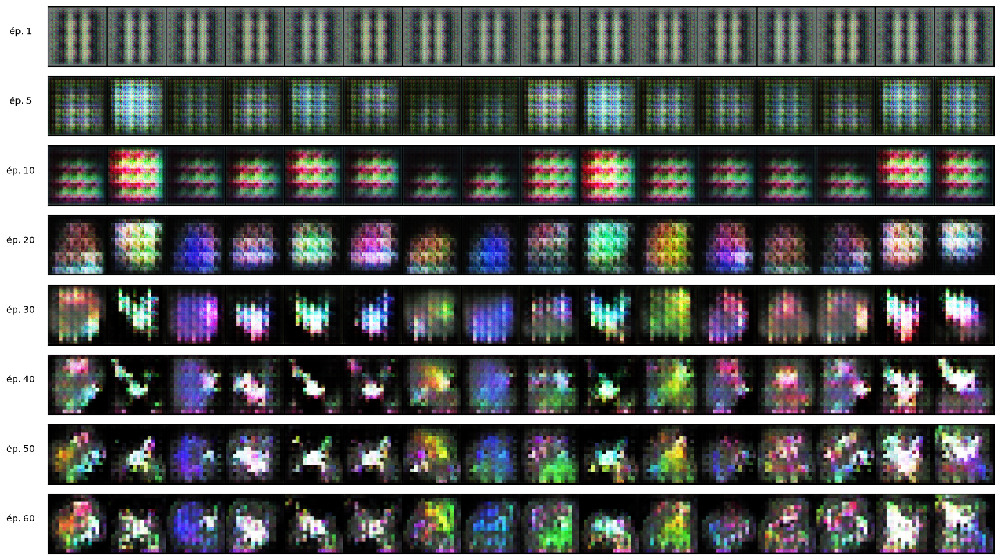

Entrenamiento concluido.


In [ ]:
import copy

def recalibrate_bn(G, n_batches=100):
    # Recalcula las estadísticas de BatchNorm para que el modo eval no dé basura
    for m in G.modules():
        if isinstance(m, nn.BatchNorm2d):
            m.reset_running_stats(); m.momentum = None
    G.train()
    with torch.no_grad():
        for _ in range(n_batches):
            G(torch.randn(256, LATENT_DIM, 1, 1, device=device))
    G.eval()

assert len(dataset) > 0, 'Dataset vacío: revisa data64_aug'
history_loss_G, history_loss_D = [], []
snaps = {}
SNAP_EPOCHS = {1, 5, 10, 20, 30, 40, 50, 60}

print('Iniciando entrenamiento con Spectral Normalization...')
for epoch in range(1, EPOCHS + 1):
    netG.train(); netD.train()
    epoch_d_loss = epoch_g_loss = 0.0
    for real_images in train_loader:
        b_size = real_images.size(0)
        real_images = real_images.to(device)
        real_labels = torch.ones(b_size, 1, device=device)
        fake_labels = torch.zeros(b_size, 1, device=device)

        optD.zero_grad()
        loss_d_real = criterion(netD(real_images), real_labels)
        fake_images = netG(torch.randn(b_size, LATENT_DIM, 1, 1, device=device))
        loss_d_fake = criterion(netD(fake_images.detach()), fake_labels)
        loss_d = loss_d_real + loss_d_fake
        loss_d.backward(); optD.step()

        optG.zero_grad()
        loss_g = criterion(netD(fake_images), real_labels)
        loss_g.backward(); optG.step()

        epoch_d_loss += loss_d.item(); epoch_g_loss += loss_g.item()

    history_loss_D.append(epoch_d_loss / len(train_loader))
    history_loss_G.append(epoch_g_loss / len(train_loader))

    if epoch in SNAP_EPOCHS or epoch == EPOCHS:
        tmp = copy.deepcopy(netG); recalibrate_bn(tmp, n_batches=20)   # misma condición que la galería
        with torch.no_grad():
            snaps[epoch] = (tmp(FIXED_NOISE_EVAL).cpu() * 0.5 + 0.5).clamp(0, 1)
        del tmp
    if epoch % 10 == 0:
        torch.save({'G': netG.state_dict(), 'D': netD.state_dict(), 'epoch': epoch},
                   f'checkpoints/spectral_ep{epoch}.pth')
    if epoch == 1 or epoch % 5 == 0:
        print(f'Época [{epoch}/{EPOCHS}] | D: {history_loss_D[-1]:.4f} | G: {history_loss_G[-1]:.4f}')

recalibrate_bn(netG)
torch.save(netG.state_dict(), 'checkpoints/netG_spectral.pth')
torch.save(netD.state_dict(), 'checkpoints/netD_spectral.pth')

# Una sola figura con la evolución del ruido fijo
eps = sorted(snaps)
fig, axes = plt.subplots(len(eps), 1, figsize=(16, 1.1 * len(eps)))
for ax, e in zip(axes, eps):
    ax.imshow(utils.make_grid(snaps[e], nrow=16, padding=1).permute(1, 2, 0).numpy())
    ax.set_ylabel(f'ép. {e}', rotation=0, labelpad=30); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.savefig('output_eval/rejilla_fija_evolucion.png', dpi=200); plt.show()
print('Entrenamiento concluido.')

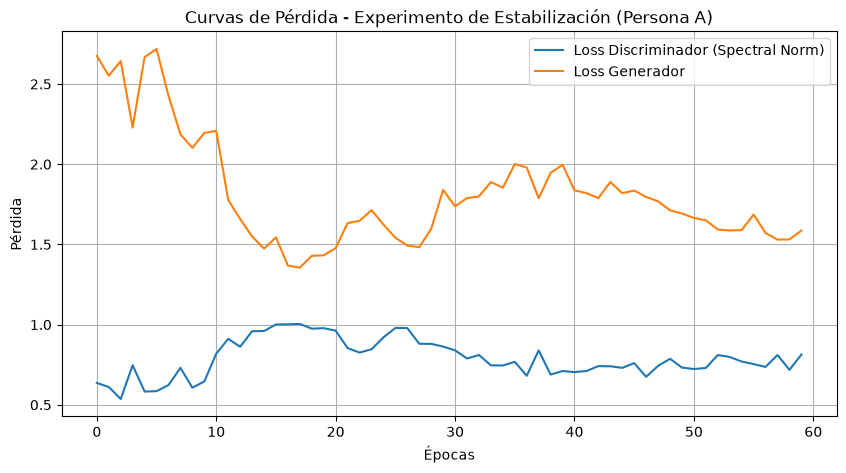

In [ ]:
# 6. Gráfica de Curvas de Pérdida
if history_loss_D:
    plt.figure(figsize=(10, 5))
    plt.plot(history_loss_D, label='Loss Discriminador (Spectral Norm)')
    plt.plot(history_loss_G, label='Loss Generador')
    plt.xlabel('Épocas')
    plt.ylabel('Pérdida')
    plt.title('Curvas de Pérdida - Experimento de Estabilización (Persona A)')
    plt.legend()
    plt.grid(True)
    plt.savefig('output_eval/curvas_perdida_persona_a.png', dpi=200)
    plt.show()


## Experimentos de pérdida y de control
Hipótesis de pérdida: "Creemos que hinge mejorará la estabilidad del entrenamiento y la nitidez de las imágenes generadas porque evita la saturación de gradientes de la sigmoide (BCE) al penalizar solo cuando las muestras violan el margen, proporcionando gradientes más consistentes al generador. Lo consideraremos útil si las curvas de pérdida muestran menor oscilación/divergencia durante las 60 épocas y las imágenes generadas presentan bordes más definidos y menor cantidad de artefactos visuales (o un menor FID si se evalúa)."
**Control:** la base usa D con BatchNorm y sin SN y BCE no saturante; hinge cambia solo la pérdida. Mismos datos, semilla 42, 60 épocas y mismo ruido fijo.
La base también sirve de control para el experimento de Spectral Norm (SN en lugar de BN).

In [ ]:
import copy, json
import torch.nn.functional as F

class DiscriminatorLogits(nn.Module):
    # Igual que DiscriminatorSpectral pero SIN Sigmoid final (devuelve logits).
    # BCEWithLogitsLoss equivale a Sigmoid + BCELoss y permite usar hinge.
    def __init__(self, channels=3, use_spectral_norm=False):
        super().__init__()
        def conv_layer(in_f, out_f, k=4, s=2, p=1, apply_bn=True):
            conv = nn.Conv2d(in_f, out_f, kernel_size=k, stride=s, padding=p, bias=not apply_bn)
            if use_spectral_norm: conv = spectral_norm(conv)
            layers = [conv]
            if apply_bn and not use_spectral_norm: layers.append(nn.BatchNorm2d(out_f))
            layers.append(nn.LeakyReLU(0.2, inplace=True))
            return layers
        last = nn.Conv2d(512, 1, kernel_size=4, stride=1, padding=0, bias=True)
        self.net = nn.Sequential(*conv_layer(channels, 64, apply_bn=False), *conv_layer(64, 128),
                                 *conv_layer(128, 256), *conv_layer(256, 512),
                                 spectral_norm(last) if use_spectral_norm else last)
    def forward(self, x): return self.net(x).view(-1, 1)

def recalibrate_bn(G, n_batches=100):
    for m in G.modules():
        if isinstance(m, nn.BatchNorm2d):
            m.reset_running_stats(); m.momentum = None
    G.train()
    with torch.no_grad():
        for _ in range(n_batches):
            G(torch.randn(256, LATENT_DIM, 1, 1, device=device))
    G.eval()

def train_run(loss_type, tag, use_sn=False, epochs=EPOCHS):
    assert loss_type in ('bce', 'hinge')
    torch.manual_seed(SEED)                      # mismo orden de creación que tu celda original
    G = Generator(LATENT_DIM, CHANNELS).to(device)
    D = DiscriminatorLogits(CHANNELS, use_spectral_norm=use_sn).to(device)
    G.apply(weights_init)
    oG = optim.Adam(G.parameters(), lr=LR, betas=(BETA1, BETA2))
    oD = optim.Adam(D.parameters(), lr=LR, betas=(BETA1, BETA2))
    bce = nn.BCEWithLogitsLoss()
    hist = {'D': [], 'G': [], 'Dx': [], 'DGz': []}
    snaps = {}
    SNAPS = {1, 5, 10, 20, 30, 40, 50, 60}
    print(f'Entrenando [{tag}] pérdida={loss_type} SN={use_sn} en {device}')
    for epoch in range(1, epochs + 1):
        G.train(); D.train()
        s = {'D': 0., 'G': 0., 'Dx': 0., 'DGz': 0.}
        for real in train_loader:
            b = real.size(0); real = real.to(device)
            ones = torch.ones(b, 1, device=device); zeros = torch.zeros(b, 1, device=device)
            oD.zero_grad()
            out_r = D(real)
            fake = G(torch.randn(b, LATENT_DIM, 1, 1, device=device))
            out_f = D(fake.detach())
            if loss_type == 'bce':
                loss_d = bce(out_r, ones) + bce(out_f, zeros)
            else:
                loss_d = F.relu(1.0 - out_r).mean() + F.relu(1.0 + out_f).mean()
            loss_d.backward(); oD.step()
            oG.zero_grad()
            out_g = D(fake)
            loss_g = bce(out_g, ones) if loss_type == 'bce' else -out_g.mean()
            loss_g.backward(); oG.step()
            s['D'] += loss_d.item(); s['G'] += loss_g.item()
            s['Dx'] += torch.sigmoid(out_r).mean().item(); s['DGz'] += torch.sigmoid(out_f).mean().item()
        for k in s: hist[k].append(s[k] / len(train_loader))
        if epoch in SNAPS or epoch == epochs:
            tmp = copy.deepcopy(G); recalibrate_bn(tmp, n_batches=20)
            with torch.no_grad():
                snaps[epoch] = (tmp(FIXED_NOISE_EVAL).cpu() * 0.5 + 0.5).clamp(0, 1)
            del tmp
        if epoch % 10 == 0:
            torch.save({'G': G.state_dict(), 'D': D.state_dict(), 'epoch': epoch}, f'checkpoints/{tag}_ep{epoch}.pth')
        if epoch == 1 or epoch % 5 == 0:
            print(f"[{tag}] época {epoch}/{epochs} | D {hist['D'][-1]:.4f} | G {hist['G'][-1]:.4f} | D(x) {hist['Dx'][-1]:.2f} | D(G(z)) {hist['DGz'][-1]:.2f}")
    recalibrate_bn(G)
    torch.save(G.state_dict(), f'checkpoints/netG_{tag}.pth')
    json.dump(hist, open(f'checkpoints/historia_{tag}.json', 'w'))
    return G, D, hist, snaps

def plot_snaps(snaps, tag):
    eps = sorted(snaps)
    fig, axes = plt.subplots(len(eps), 1, figsize=(16, 1.1 * len(eps)))
    for ax, e in zip(axes, eps):
        ax.imshow(utils.make_grid(snaps[e], nrow=16, padding=1).permute(1, 2, 0).numpy())
        ax.set_ylabel(f'ép. {e}', rotation=0, labelpad=30); ax.set_xticks([]); ax.set_yticks([])
    plt.suptitle(f'Rejilla de ruido fijo ({tag})'); plt.tight_layout()
    plt.savefig(f'output_eval/rejilla_fija_{tag}.png', dpi=200); plt.show()

def plot_curves(hist, tag):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(hist['D'], label='D'); ax[0].plot(hist['G'], label='G'); ax[0].set_title(f'Pérdidas ({tag})'); ax[0].legend(); ax[0].grid(True)
    ax[1].plot(hist['Dx'], label='D(x) real'); ax[1].plot(hist['DGz'], label='D(G(z)) falso'); ax[1].set_title('Salidas de D (probabilidad)'); ax[1].legend(); ax[1].grid(True)
    plt.tight_layout(); plt.savefig(f'output_eval/curvas_{tag}.png', dpi=200); plt.show()

Entrenando [base] pérdida=bce SN=False en cpu
[base] época 1/60 | D 0.5530 | G 8.6683 | D(x) 0.88 | D(G(z)) 0.18
[base] época 5/60 | D 0.1156 | G 5.6028 | D(x) 0.94 | D(G(z)) 0.05
[base] época 10/60 | D 0.2906 | G 5.5482 | D(x) 0.92 | D(G(z)) 0.07
[base] época 15/60 | D 0.4547 | G 4.6407 | D(x) 0.87 | D(G(z)) 0.14
[base] época 20/60 | D 0.2701 | G 4.2550 | D(x) 0.90 | D(G(z)) 0.11
[base] época 25/60 | D 0.0974 | G 4.7057 | D(x) 0.96 | D(G(z)) 0.05
[base] época 30/60 | D 0.4338 | G 4.0129 | D(x) 0.88 | D(G(z)) 0.11
[base] época 35/60 | D 0.0696 | G 4.5377 | D(x) 0.97 | D(G(z)) 0.03
[base] época 40/60 | D 0.5923 | G 4.7520 | D(x) 0.90 | D(G(z)) 0.09
[base] época 45/60 | D 0.3791 | G 4.4558 | D(x) 0.90 | D(G(z)) 0.10
[base] época 50/60 | D 0.6273 | G 5.0638 | D(x) 0.90 | D(G(z)) 0.08
[base] época 55/60 | D 0.0582 | G 5.1495 | D(x) 0.97 | D(G(z)) 0.03
[base] época 60/60 | D 0.2695 | G 5.9226 | D(x) 0.96 | D(G(z)) 0.03


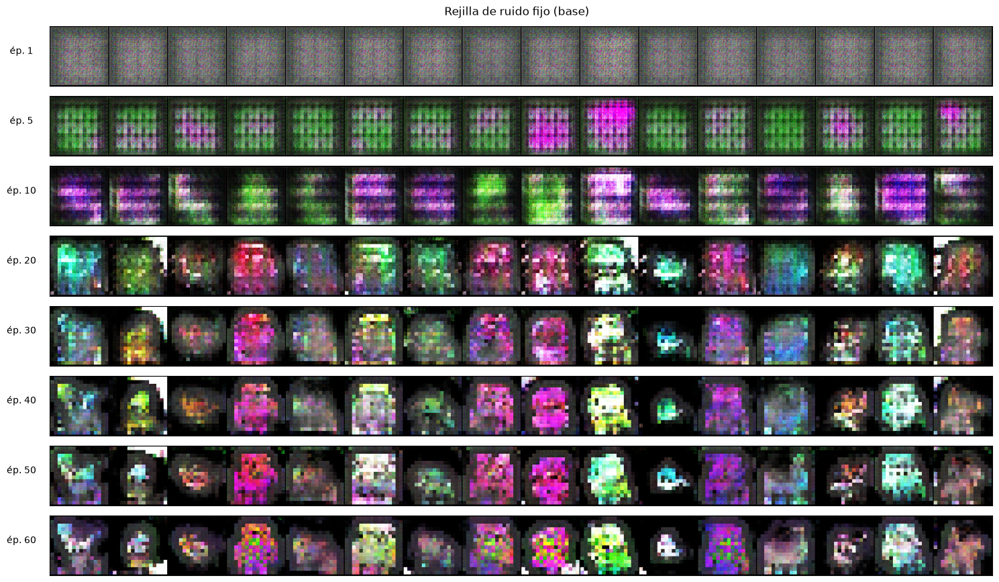

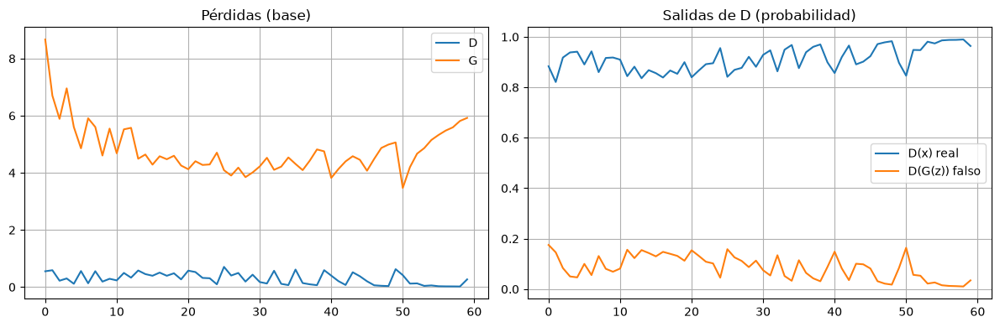

In [ ]:
G_base, D_base, hist_base, snaps_base = train_run('bce', 'base')
plot_snaps(snaps_base, 'base'); plot_curves(hist_base, 'base')

Entrenando [hinge] pérdida=hinge SN=False en cpu
[hinge] época 1/60 | D 0.8410 | G 6.3031 | D(x) 0.83 | D(G(z)) 0.23
[hinge] época 5/60 | D 0.1654 | G 4.8448 | D(x) 0.90 | D(G(z)) 0.10
[hinge] época 10/60 | D 0.5233 | G 3.9629 | D(x) 0.82 | D(G(z)) 0.18
[hinge] época 15/60 | D 0.4029 | G 3.1716 | D(x) 0.82 | D(G(z)) 0.17
[hinge] época 20/60 | D 0.3715 | G 3.4641 | D(x) 0.84 | D(G(z)) 0.16
[hinge] época 25/60 | D 0.3033 | G 2.9846 | D(x) 0.83 | D(G(z)) 0.16
[hinge] época 30/60 | D 0.0631 | G 2.6490 | D(x) 0.88 | D(G(z)) 0.12
[hinge] época 35/60 | D 0.0513 | G 2.8963 | D(x) 0.89 | D(G(z)) 0.10
[hinge] época 40/60 | D 0.0620 | G 2.7966 | D(x) 0.89 | D(G(z)) 0.10
[hinge] época 45/60 | D 0.0165 | G 2.8330 | D(x) 0.91 | D(G(z)) 0.09
[hinge] época 50/60 | D 0.1083 | G 2.8891 | D(x) 0.88 | D(G(z)) 0.12
[hinge] época 55/60 | D 0.0282 | G 3.1591 | D(x) 0.91 | D(G(z)) 0.08
[hinge] época 60/60 | D 0.1691 | G 3.2511 | D(x) 0.88 | D(G(z)) 0.12


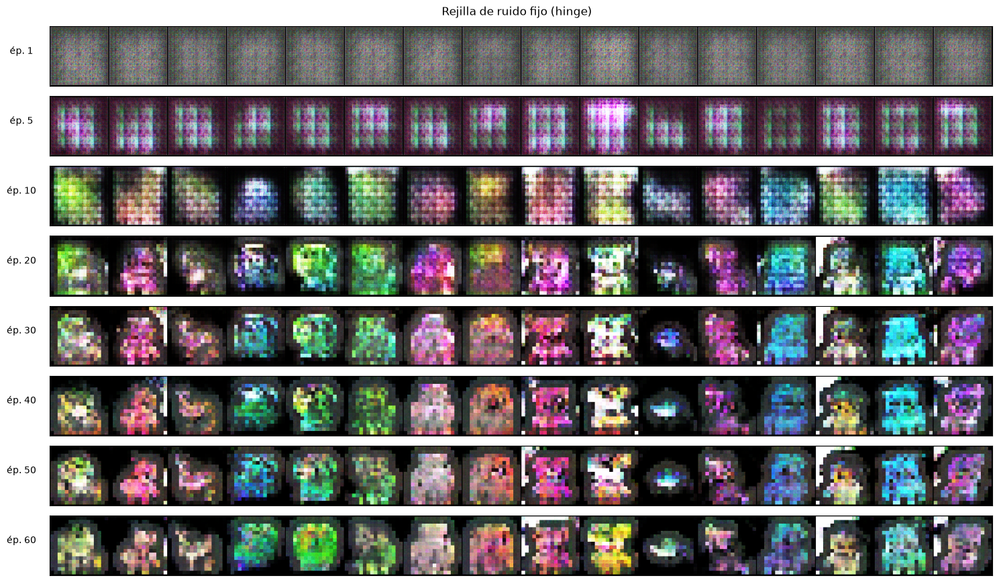

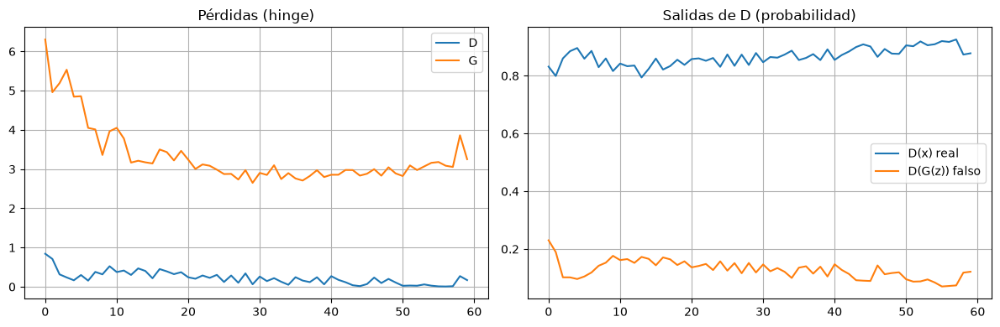

In [ ]:
G_hinge, D_hinge, hist_hinge, snaps_hinge = train_run('hinge', 'hinge')
plot_snaps(snaps_hinge, 'hinge'); plot_curves(hist_hinge, 'hinge')

Diversidad (distancia media entre pares, 256 muestras; mayor = más variadas):
  real (referencia)    0.3496
  base (BCE)           0.3308
  hinge                0.3333
  Spectral Norm        0.2676


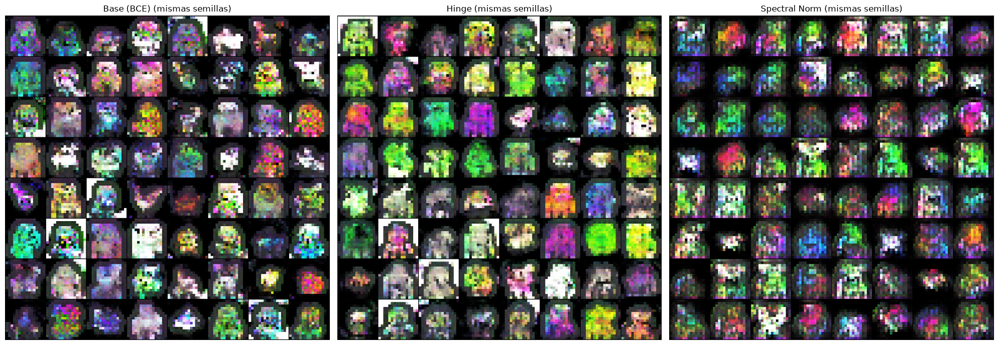

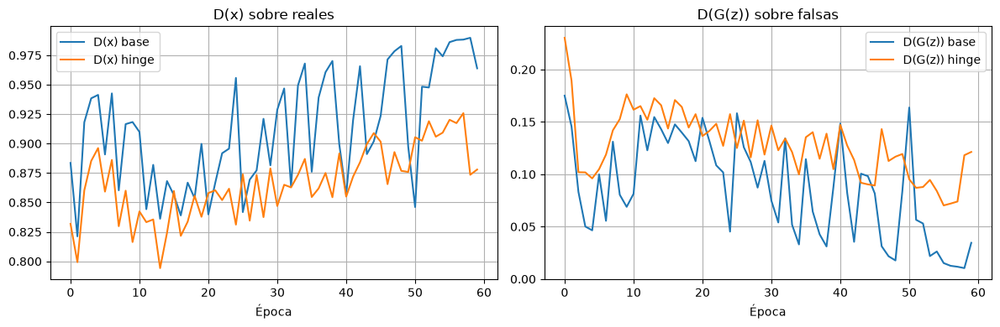

In [ ]:
@torch.no_grad()
def sample(G, n=256, seed=777):
    G.eval()
    z = torch.randn(n, LATENT_DIM, 1, 1, generator=torch.Generator().manual_seed(seed)).to(device)
    return (G(z).cpu() * 0.5 + 0.5).clamp(0, 1)

def mean_pairwise(x):
    f = x.flatten(1); d = torch.cdist(f, f); n = len(f)
    return d.sum().item() / (n * (n - 1)) / (f.shape[1] ** 0.5)

idx = random.Random(0).sample(range(len(dataset)), 256)
x_real = torch.stack([dataset[i] for i in idx]) * 0.5 + 0.5
x_base, x_hinge, x_sn = sample(G_base), sample(G_hinge), sample(netG)   # netG = tu corrida con Spectral Norm

div = {'real (referencia)': mean_pairwise(x_real), 'base (BCE)': mean_pairwise(x_base),
       'hinge': mean_pairwise(x_hinge), 'Spectral Norm': mean_pairwise(x_sn)}
print('Diversidad (distancia media entre pares, 256 muestras; mayor = más variadas):')
for k, v in div.items(): print(f'  {k:20s} {v:.4f}')

fig, axes = plt.subplots(1, 3, figsize=(20, 7))
for ax, x, t in zip(axes, (x_base, x_hinge, x_sn), ('Base (BCE)', 'Hinge', 'Spectral Norm')):
    ax.imshow(utils.make_grid(x[:64], nrow=8, padding=1).permute(1, 2, 0).numpy()); ax.set_title(f'{t} (mismas semillas)'); ax.axis('off')
plt.tight_layout(); plt.savefig('output_eval/comparacion_modelos.png', dpi=200); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for h, name in ((hist_base, 'base'), (hist_hinge, 'hinge')):
    ax[0].plot(h['Dx'], label=f'D(x) {name}'); ax[1].plot(h['DGz'], label=f'D(G(z)) {name}')
ax[0].set_title('D(x) sobre reales'); ax[1].set_title('D(G(z)) sobre falsas')
for a in ax: a.set_xlabel('Época'); a.legend(); a.grid(True)
plt.tight_layout(); plt.savefig('output_eval/comparacion_salidas_D.png', dpi=200); plt.show()

In [ ]:
netG = Generator(LATENT_DIM, CHANNELS).to(device)
netG.load_state_dict(torch.load('checkpoints/netG_hinge.pth', map_location=device))
netG.eval()

Generator(
  (net): Sequential(
    (0): ConvTranspose2d(100, 512, kernel_size=(4, 4), stride=(1, 1), bias=False)
    (1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): ConvTranspose2d(512, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (4): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (7): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (8): ReLU(inplace=True)
    (9): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (10): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (11): ReLU(inplace=True)
    (12): ConvTranspose2d(64, 3, kernel_size=(4, 4), stride=(2, 2), padding=

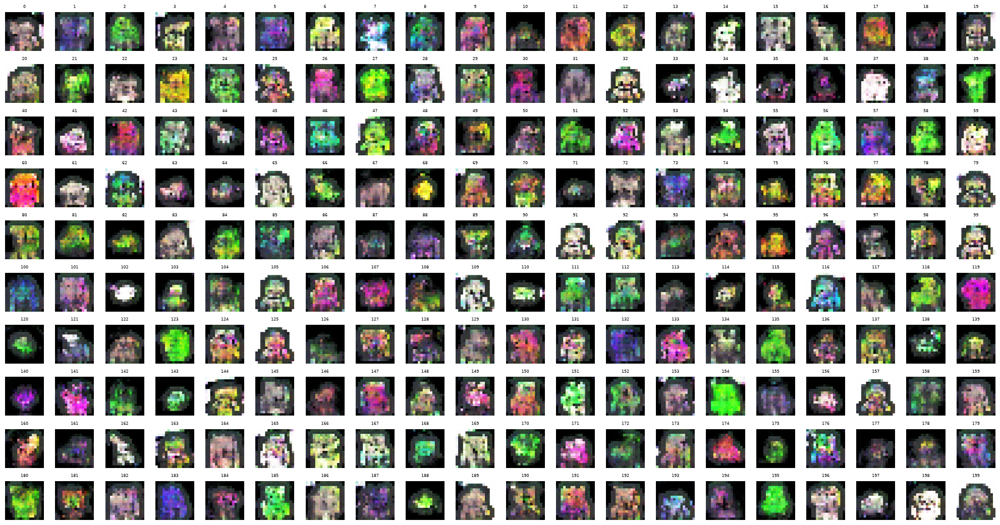

TASA DE SELECCIÓN: 10 de 200 (5.0%)
CRITERIO: Se eligieron muestras con silueta central perceptible y contraste claro frente al fondo negro, que evitaran manchas amorfas o exceso de ruido disperso, buscando cubrir variedad de tonos (verdes, cálidos, celestes, blancos) y posturas dentro del nivel de definición alcanzado por el modelo.
Galería guardada.


In [17]:
TOTAL_CANDIDATOS = 200
netG.eval()
candidatos_z, candidatos_img = [], []

with torch.no_grad():
    for idx in range(TOTAL_CANDIDATOS):
        sample_seed = 1000 + idx
        z = torch.randn(1, LATENT_DIM, 1, 1, generator=torch.Generator().manual_seed(sample_seed))
        img = (netG(z.to(device)).cpu() * 0.5 + 0.5).clamp(0, 1)
        candidatos_z.append((sample_seed, z))
        candidatos_img.append(img.squeeze(0))

fig, axes = plt.subplots(10, 20, figsize=(20, 10.5))
for i, ax in enumerate(axes.flat):
    ax.imshow(candidatos_img[i].permute(1, 2, 0))
    ax.set_title(str(i), fontsize=6)
    ax.axis('off')
plt.tight_layout()
plt.savefig('output_eval/candidatos.png', dpi=200)
plt.show()

# 10 índices con silueta clara, buen contraste y variedad de color/arquetipo
selected_indices = [4, 14, 29, 45, 64, 104, 110, 112, 154, 184]
assert len(selected_indices) == 10 and len(set(selected_indices)) == 10, 'Elige 10 índices distintos'

criterio_texto = "Se eligieron muestras con silueta central perceptible y contraste claro frente al fondo negro, que evitaran manchas amorfas o exceso de ruido disperso, buscando cubrir variedad de tonos (verdes, cálidos, celestes, blancos) y posturas dentro del nivel de definición alcanzado por el modelo."

print(f'TASA DE SELECCIÓN: 10 de {TOTAL_CANDIDATOS} ({10/TOTAL_CANDIDATOS:.1%})')
print(f'CRITERIO: {criterio_texto}')

with open('galeria/semillas.txt', 'w') as f:
    for pos, i in enumerate(selected_indices, start=1):
        seed_val, z = candidatos_z[i]
        utils.save_image(candidatos_img[i], f'galeria/personaje_{pos:02d}_seed_{seed_val}.png')
        torch.save(z, f'galeria/personaje_{pos:02d}_z.pt')
        f.write(f'personaje_{pos:02d}\tindice={i}\tseed={seed_val}\n')
print('Galería guardada.')


Original vs original: mediana 0.974 | p90 0.984 | máx 0.994


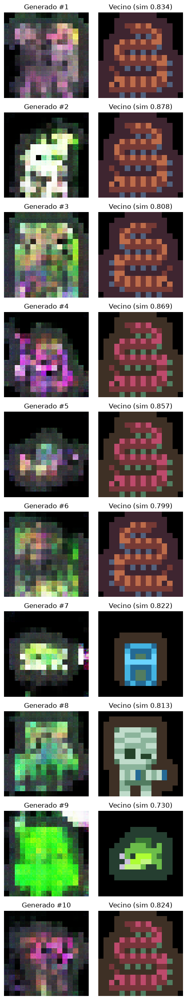

Similitudes: [0.834, 0.878, 0.808, 0.869, 0.857, 0.799, 0.822, 0.813, 0.73, 0.824]
Personaje más difícil de defender como nuevo: # 2


In [ ]:
weights = models.ResNet18_Weights.DEFAULT
feature_extractor = models.resnet18(weights=weights); feature_extractor.fc = nn.Identity()
feature_extractor = feature_extractor.to(device).eval()
resnet_transform = transforms.Compose([
    transforms.Resize((224, 224), interpolation=transforms.InterpolationMode.NEAREST),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

@torch.no_grad()
def extract_features(x01):
    return feature_extractor(resnet_transform(x01.to(device))).cpu().numpy()

def dataset_features(ds):
    loader = DataLoader(ds, batch_size=128, shuffle=False, drop_last=False)   # sin shuffle ni imágenes perdidas
    F, I = [], []
    for b in loader:
        x = b * 0.5 + 0.5
        F.append(extract_features(x)); I.append(x)
    return np.vstack(F), torch.cat(I)

real_features, real_imgs = dataset_features(dataset)

# Vara de comparación: cada ORIGINAL contra su vecino más cercano distinto de sí mismo
orig_ds = PixelArtDataset('data64', transform=transform)
oF, _ = dataset_features(orig_ds)
S = cosine_similarity(oF); np.fill_diagonal(S, -1); nn_orig = S.max(1)
print(f'Original vs original: mediana {np.median(nn_orig):.3f} | p90 {np.percentile(nn_orig, 90):.3f} | máx {nn_orig.max():.3f}')

fig, axes = plt.subplots(10, 2, figsize=(5, 25))
sims = []
for k, i in enumerate(selected_indices):
    gi = candidatos_img[i]
    s = cosine_similarity(extract_features(gi.unsqueeze(0)), real_features)[0]
    j = int(np.argmax(s)); sims.append(float(s[j]))
    axes[k, 0].imshow(gi.permute(1, 2, 0)); axes[k, 0].set_title(f'Generado #{k+1}'); axes[k, 0].axis('off')
    axes[k, 1].imshow(real_imgs[j].permute(1, 2, 0)); axes[k, 1].set_title(f'Vecino (sim {s[j]:.3f})'); axes[k, 1].axis('off')
plt.tight_layout(); plt.savefig('output_eval/vecinos_mas_cercanos.png', dpi=200); plt.show()
print('Similitudes:', [round(x, 3) for x in sims])
print('Personaje más difícil de defender como nuevo: #', int(np.argmax(sims)) + 1)

In [18]:
test_G = Generator(LATENT_DIM, CHANNELS).to(device)
test_G.load_state_dict(torch.load('checkpoints/netG_hinge.pth', map_location=device)); test_G.eval()
ok = True
for pos, i in enumerate(selected_indices, start=1):
    seed_val = candidatos_z[i][0]
    z = torch.load(f'galeria/personaje_{pos:02d}_z.pt').to(device)
    with torch.no_grad():
        regen = (test_G(z).cpu() * 0.5 + 0.5).clamp(0, 1).squeeze(0)
    saved = transforms.ToTensor()(Image.open(f'galeria/personaje_{pos:02d}_seed_{seed_val}.png').convert('RGB'))
    err = (regen - saved).abs().max().item()
    ok &= err < 2 / 255
    print(f'personaje {pos:02d}: error máx = {err:.5f}')
print('¿Galería regenerable desde pesos + z?:', 'SÍ' if ok else 'NO')

personaje 01: error máx = 0.00196
personaje 02: error máx = 0.00196
personaje 03: error máx = 0.00196
personaje 04: error máx = 0.00196
personaje 05: error máx = 0.00196
personaje 06: error máx = 0.00196
personaje 07: error máx = 0.00196
personaje 08: error máx = 0.00196
personaje 09: error máx = 0.00196
personaje 10: error máx = 0.00196
¿Galería regenerable desde pesos + z?: SÍ


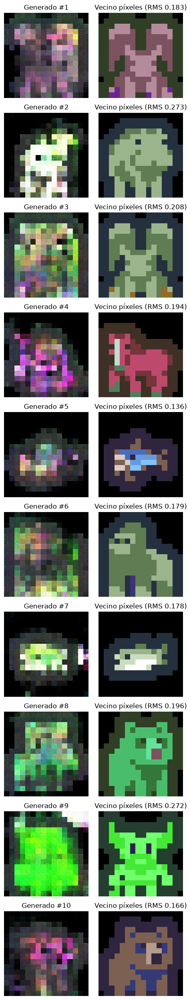

RMS por personaje: [0.183, 0.273, 0.208, 0.194, 0.136, 0.179, 0.178, 0.196, 0.272, 0.166]


In [16]:
gen = torch.stack([candidatos_img[i] for i in selected_indices])
d = torch.cdist(gen.flatten(1), real_imgs.flatten(1)) / (3 * 64 * 64) ** 0.5
dmin, jmin = d.min(1)
fig, axes = plt.subplots(10, 2, figsize=(5, 25))
for k in range(10):
    axes[k, 0].imshow(gen[k].permute(1, 2, 0)); axes[k, 0].set_title(f'Generado #{k+1}'); axes[k, 0].axis('off')
    axes[k, 1].imshow(real_imgs[jmin[k]].permute(1, 2, 0)); axes[k, 1].set_title(f'Vecino píxeles (RMS {dmin[k]:.3f})'); axes[k, 1].axis('off')
plt.tight_layout(); plt.savefig('output_eval/vecinos_pixeles.png', dpi=200); plt.show()
print('RMS por personaje:', [round(float(x), 3) for x in dmin])